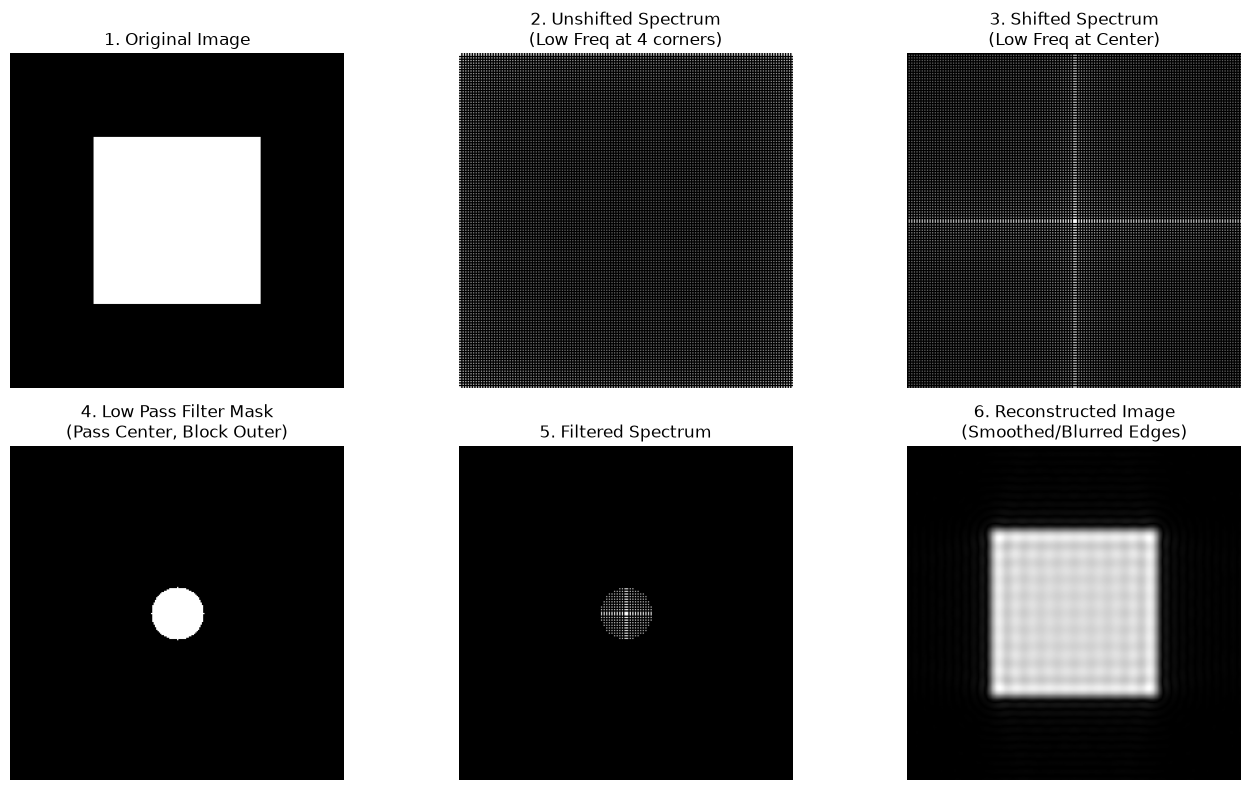

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. สร้างภาพจำลอง (รูปสี่เหลี่ยมสีขาวตรงกลาง บนพื้นหลังสีดำ)
size = 256
img = np.zeros((size, size))
img[size//4 : 3*size//4, size//4 : 3*size//4] = 255

# 2. แปลงเป็น 2D Spectrum ด้วย FFT
f_transform = np.fft.fft2(img)

# ใช้ log(1 + |F|) เพื่อปรับ Scale ให้มองเห็นความถี่สูงได้ชัดเจนขึ้น
spectrum_unshifted = np.log(1 + np.abs(f_transform))

# 3. ทำ Shift (ย้ายความถี่ต่ำ DC มาไว้ตรงกลาง)
f_shift = np.fft.fftshift(f_transform)
spectrum_shifted = np.log(1 + np.abs(f_shift))

# 4. สร้างหน้ากาก Low Pass Filter (วงกลมตรงกลาง)
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2
radius = 20  # รัศมีของความถี่ต่ำที่ยอมให้ผ่าน

y, x = np.ogrid[:rows, :cols]
lpf_mask = (x - ccol)**2 + (y - crow)**2 <= radius**2

# 5. นำ LPF ไปตัดความถี่สูงรอบนอกทิ้ง (Coefficient Editing)
f_shift_filtered = f_shift * lpf_mask
spectrum_filtered = np.log(1 + np.abs(f_shift_filtered))

# 6. แปลงกลับเป็นรูปภาพด้วย Inverse FFT (ต้อง Unshift กลับก่อน)
f_unshifted_filtered = np.fft.ifftshift(f_shift_filtered)
img_reconstructed = np.abs(np.fft.ifft2(f_unshifted_filtered))

# --- แสดงผลเปรียบเทียบภาพในแต่ละขั้นตอน ---
plt.figure(figsize=(14, 8))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap='gray')
plt.title("1. Original Image")
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(spectrum_unshifted, cmap='gray')
plt.title("2. Unshifted Spectrum\n(Low Freq at 4 corners)")
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(spectrum_shifted, cmap='gray')
plt.title("3. Shifted Spectrum\n(Low Freq at Center)")
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(lpf_mask, cmap='gray')
plt.title("4. Low Pass Filter Mask\n(Pass Center, Block Outer)")
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(spectrum_filtered, cmap='gray')
plt.title("5. Filtered Spectrum")
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(img_reconstructed, cmap='gray')
plt.title("6. Reconstructed Image\n(Smoothed/Blurred Edges)")
plt.axis('off')

plt.tight_layout()
plt.show()

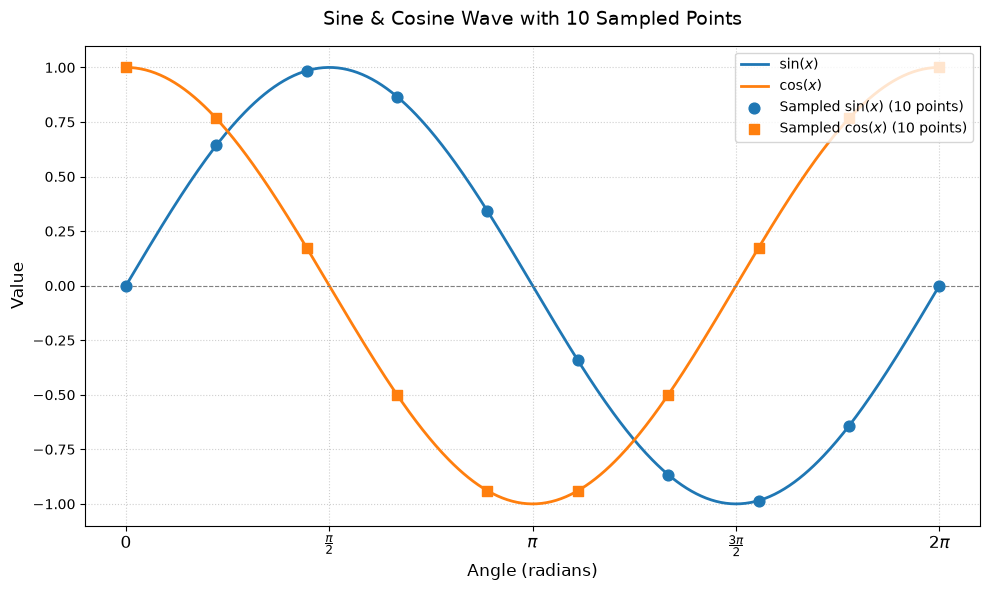

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. กำหนดช่วงข้อมูลสำหรับเส้นกราฟแบบต่อเนื่อง (0 ถึง 2π)
x_continuous = np.linspace(0, 2 * np.pi, 500)
y_sin = np.sin(x_continuous)
y_cos = np.cos(x_continuous)

# 2. Sample ข้อมูลจำนวน 10 จุด
x_sampled = np.linspace(0, 2 * np.pi, 10)
y_sin_sampled = np.sin(x_sampled)
y_cos_sampled = np.cos(x_sampled)

# 3. สร้างกราฟ
plt.figure(figsize=(10, 6), dpi=100)

# วาดเส้นกราฟ sin และ cos
plt.plot(x_continuous, y_sin, label=r'$\sin(x)$', color='#1f77b4', linewidth=2)
plt.plot(x_continuous, y_cos, label=r'$\cos(x)$', color='#ff7f0e', linewidth=2)

# แสดงจุด Sampling 10 จุด
plt.scatter(x_sampled, y_sin_sampled, color='#1f77b4', s=60, zorder=5, label=r'Sampled $\sin(x)$ (10 points)')
plt.scatter(x_sampled, y_cos_sampled, color='#ff7f0e', marker='s', s=60, zorder=5, label=r'Sampled $\cos(x)$ (10 points)')

# 4. ตั้งค่าแกน X ให้แสดงผลเป็นหน่วย Radian (0, π/2, π, 3π/2, 2π)
ticks = [0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi]
labels = ['$0$', r'$\frac{\pi}{2}$', r'$\pi$', r'$\frac{3\pi}{2}$', r'$2\pi$']
plt.xticks(ticks, labels, fontsize=12)

# 5. ตกแต่งกราฟ
plt.title('Sine & Cosine Wave with 10 Sampled Points', fontsize=14, pad=15)
plt.xlabel('Angle (radians)', fontsize=12)
plt.ylabel('Value', fontsize=12)
plt.axhline(0, color='gray', linewidth=0.8, linestyle='--')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()


In [4]:
x_sampled

array([0.        , 0.6981317 , 1.3962634 , 2.0943951 , 2.7925268 ,
       3.4906585 , 4.1887902 , 4.88692191, 5.58505361, 6.28318531])

In [5]:
y_sin_sampled

array([ 0.00000000e+00,  6.42787610e-01,  9.84807753e-01,  8.66025404e-01,
        3.42020143e-01, -3.42020143e-01, -8.66025404e-01, -9.84807753e-01,
       -6.42787610e-01, -2.44929360e-16])

In [11]:
import numpy as np

# 1. เตรียมข้อมูลจากขั้นตอนที่แล้ว (N = 10 จุด)
N = 10
x_sampled = np.linspace(0, 2 * np.pi, N)
y_sin_sampled = np.sin(x_sampled)  # คือ f(x) ในสูตร

# 2. แปลงสูตร DFT: F(k) = (1/N) * sum_{x=0}^{N-1} f(x) * e^(-j * 2 * pi * k * x / N)

# --- แบบที่ 1: เขียน Loop ตรงตามสูตร ---
F_k = np.zeros(N, dtype=complex)

for k in range(N):
    sum_val = 0
    for x_idx in range(N):
        # คำนวณ f(x) * e^(-j * 2 * pi * k * x / N)
        term = y_sin_sampled[x_idx] * np.exp(-1j * 2 * np.pi * k * x_idx / N)
        sum_val += term
    F_k[k] = (1 / N) * sum_val

# --- แบบที่ 2: ใช้ Matrix Vectorization ของ NumPy (คำนวณเร็วกว่า) ---
k_vec = np.arange(N)
x_vec = np.arange(N)
# สร้าง DFT Matrix
W = np.exp(-1j * 2 * np.pi * np.outer(k_vec, x_vec) / N)
F_k_vectorized = (1 / N) * (W @ y_sin_sampled)

# 3. แสดงผลลัพธ์การคำนวณ F(k)
print("ผลลัพธ์ F(k) สำหรับ k = 0 ถึง 9:")
print("-" * 55)
for k_val, val in enumerate(F_k):
    magnitude = np.abs(val)
    phase = np.angle(val)
    print(f"F({k_val}) = {val.real:+.4f} {val.imag:+.4f}j  | Magnitude = {magnitude:.4f}")

ผลลัพธ์ F(k) สำหรับ k = 0 ถึง 9:
-------------------------------------------------------
F(0) = -0.0000 +0.0000j  | Magnitude = 0.0000
F(1) = +0.1428 -0.4396j  | Magnitude = 0.4622
F(2) = -0.0486 +0.0669j  | Magnitude = 0.0827
F(3) = -0.0391 +0.0284j  | Magnitude = 0.0484
F(4) = -0.0369 +0.0120j  | Magnitude = 0.0388
F(5) = -0.0364 -0.0000j  | Magnitude = 0.0364
F(6) = -0.0369 -0.0120j  | Magnitude = 0.0388
F(7) = -0.0391 -0.0284j  | Magnitude = 0.0484
F(8) = -0.0486 -0.0669j  | Magnitude = 0.0827
F(9) = +0.1428 +0.4396j  | Magnitude = 0.4622


In [12]:
# =========================================================
# 4. Inverse Discrete Fourier Transform (IDFT)
# สูตร: f(x) = sum_{k=0}^{N-1} F(k) * e^(+j * 2 * pi * k * x / N)
# =========================================================

# --- แบบที่ 1: เขียน Loop ตรงตามสูตร IDFT ---
f_reconstructed = np.zeros(N, dtype=complex)

for x_idx in range(N):
    sum_val = 0
    for k in range(N):
        # หมายเหตุ: ใน IDFT เลขชี้กำลังของ e จะเปลี่ยนเป็นเครื่องหมายบวก (+1j)
        term = F_k[k] * np.exp(1j * 2 * np.pi * k * x_idx / N)
        sum_val += term
    f_reconstructed[x_idx] = sum_val

# ดึงเฉพาะส่วนจริง (Real part) ออกมา เนื่องจากสัญญาณต้นฉบับเป็นเลขจริง
f_reconstructed_real = f_reconstructed.real


# --- แบบที่ 2: ใช้ Matrix Vectorization (NumPy) ---
W_inv = np.exp(1j * 2 * np.pi * np.outer(x_vec, k_vec) / N)
f_reconstructed_vec = (W_inv @ F_k).real


# 5. แสดงผลลัพธ์เปรียบเทียบสัญญาณเดิมกับสัญญาณที่กู้คืนมาได้
print("\nผลลัพธ์การ Inverse DFT (กู้คืนสัญญาณกลับมา):")
print("-" * 60)
for i in range(N):
    print(f"จุดที่ {i}: สัญญาณเดิม = {y_sin_sampled[i]:+.4f} | กู้คืนได้ (IDFT) = {f_reconstructed_real[i]:+.4f}")



ผลลัพธ์การ Inverse DFT (กู้คืนสัญญาณกลับมา):
------------------------------------------------------------
จุดที่ 0: สัญญาณเดิม = +0.0000 | กู้คืนได้ (IDFT) = +0.0000
จุดที่ 1: สัญญาณเดิม = +0.6428 | กู้คืนได้ (IDFT) = +0.6428
จุดที่ 2: สัญญาณเดิม = +0.9848 | กู้คืนได้ (IDFT) = +0.9848
จุดที่ 3: สัญญาณเดิม = +0.8660 | กู้คืนได้ (IDFT) = +0.8660
จุดที่ 4: สัญญาณเดิม = +0.3420 | กู้คืนได้ (IDFT) = +0.3420
จุดที่ 5: สัญญาณเดิม = -0.3420 | กู้คืนได้ (IDFT) = -0.3420
จุดที่ 6: สัญญาณเดิม = -0.8660 | กู้คืนได้ (IDFT) = -0.8660
จุดที่ 7: สัญญาณเดิม = -0.9848 | กู้คืนได้ (IDFT) = -0.9848
จุดที่ 8: สัญญาณเดิม = -0.6428 | กู้คืนได้ (IDFT) = -0.6428
จุดที่ 9: สัญญาณเดิม = -0.0000 | กู้คืนได้ (IDFT) = +0.0000


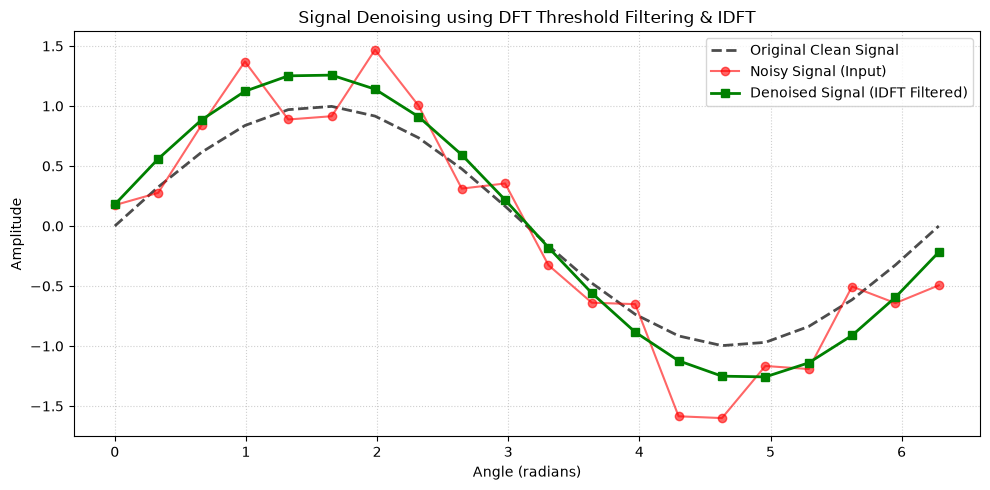

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# 1. สร้างสัญญาณสะอาดเดิม + ใส่ Noise (สัญญาณรบกวน)
N = 20  # ใช้ 20 จุดเพื่อให้เห็นผลลัพธ์ความถี่และการกรองที่ชัดเจนขึ้น
x_sampled = np.linspace(0, 2 * np.pi, N)
y_clean = np.sin(x_sampled)

# สุ่มใส่ Gaussian Noise
np.random.seed(42)  # ล็อก seed เพื่อให้สุ่มได้ค่าเดิมทุกครั้ง
noise = np.random.normal(0, 0.35, N)
y_noisy = y_clean + noise  # สัญญาณที่มี Noise

# 2. แปลงสัญญาณที่มี Noise เป็น Frequency Domain ด้วย DFT
k_vec = np.arange(N)
x_vec = np.arange(N)
W = np.exp(-1j * 2 * np.pi * np.outer(k_vec, x_vec) / N)
F_k_noisy = (1 / N) * (W @ y_noisy)

# 3. --- ขั้นตอน Remove Noise (Threshold Filtering) ---
# กำหนดค่า Threshold (ถ้า Magnitude ของความถี่ไหนต่ำกว่า 0.2 ให้ตัดเป็น 0)
threshold = 0.2
F_k_filtered = F_k_noisy.copy()
F_k_filtered[np.abs(F_k_noisy) < threshold] = 0

# 4. แปลงสัญญาณที่กรองแล้วกลับด้วย IDFT
W_inv = np.exp(1j * 2 * np.pi * np.outer(x_vec, k_vec) / N)
y_denoised = (W_inv @ F_k_filtered).real

# 5. วาดกราฟเปรียบเทียบ
plt.figure(figsize=(10, 5), dpi=100)

plt.plot(x_sampled, y_clean, 'k--', label='Original Clean Signal', alpha=0.7, linewidth=2)
plt.plot(x_sampled, y_noisy, 'r-o', label='Noisy Signal (Input)', alpha=0.6)
plt.plot(x_sampled, y_denoised, 'g-s', label='Denoised Signal (IDFT Filtered)', linewidth=2)

plt.title('Signal Denoising using DFT Threshold Filtering & IDFT', fontsize=12)
plt.xlabel('Angle (radians)')
plt.ylabel('Amplitude')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()


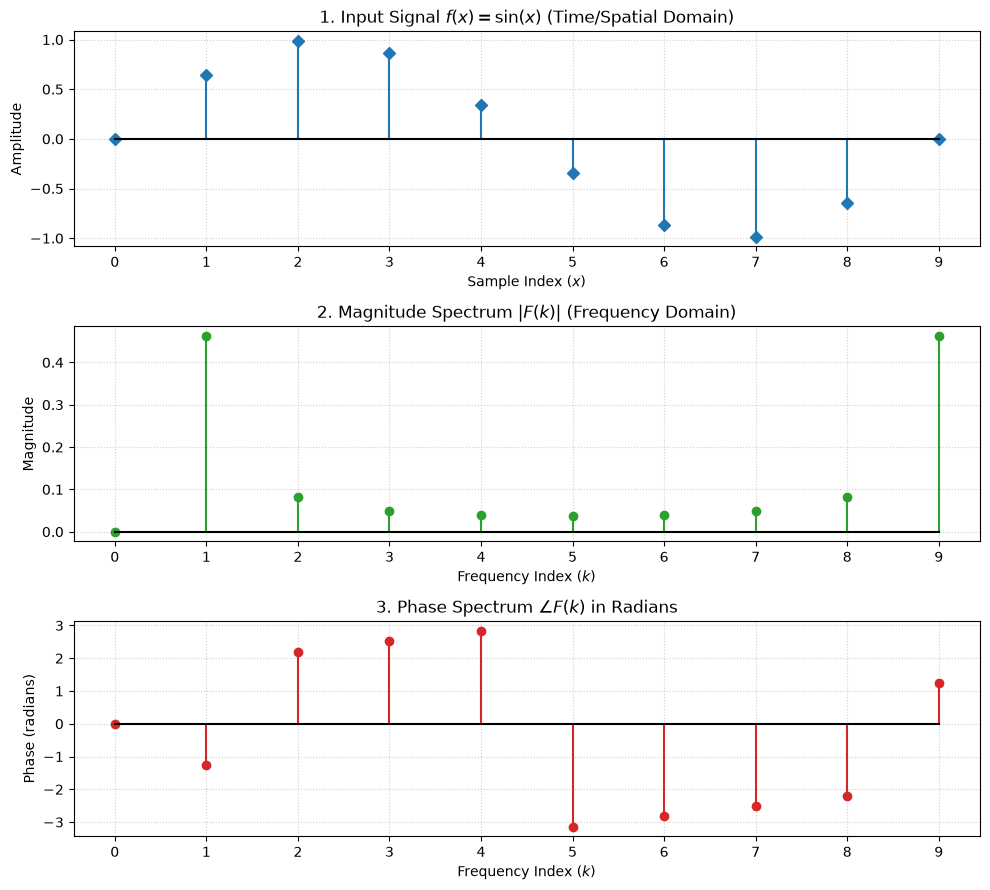

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# 1. คำนวณข้อมูลเดิม
N = 10
x_idx = np.arange(N)
x_sampled = np.linspace(0, 2 * np.pi, N)
y_sin_sampled = np.sin(x_sampled)

# 2. คำนวณ DFT F(k)
k_vec = np.arange(N)
W = np.exp(-1j * 2 * np.pi * np.outer(k_vec, x_idx) / N)
F_k = (1 / N) * (W @ y_sin_sampled)

magnitudes = np.abs(F_k)
phases = np.angle(F_k)

# 3. วาดกราฟ 3 Subplots
fig, axes = plt.subplots(3, 1, figsize=(10, 9), dpi=100)

# --- กราฟที่ 1: สัญญาณอินพุต f(x) ---
axes[0].stem(x_idx, y_sin_sampled, linefmt='C0-', markerfmt='C0D', basefmt='k-')
axes[0].set_title(r'1. Input Signal $f(x) = \sin(x)$ (Time/Spatial Domain)', fontsize=12)
axes[0].set_xlabel('Sample Index ($x$)', fontsize=10)
axes[0].set_ylabel('Amplitude', fontsize=10)
axes[0].set_xticks(x_idx)
axes[0].grid(True, linestyle=':', alpha=0.6)

# --- กราฟที่ 2: ขนาดความแรงความถี่ |F(k)| ---
axes[1].stem(k_vec, magnitudes, linefmt='C2-', markerfmt='C2o', basefmt='k-')
axes[1].set_title(r'2. Magnitude Spectrum $|F(k)|$ (Frequency Domain)', fontsize=12)
axes[1].set_xlabel('Frequency Index ($k$)', fontsize=10)
axes[1].set_ylabel('Magnitude', fontsize=10)
axes[1].set_xticks(k_vec)
axes[1].grid(True, linestyle=':', alpha=0.6)

# --- กราฟที่ 3: เฟสของความถี่ Phase F(k) ---
axes[2].stem(k_vec, phases, linefmt='C3-', markerfmt='C3o', basefmt='k-')
axes[2].set_title(r'3. Phase Spectrum $\angle F(k)$ in Radians', fontsize=12)
axes[2].set_xlabel('Frequency Index ($k$)', fontsize=10)
axes[2].set_ylabel('Phase (radians)', fontsize=10)
axes[2].set_xticks(k_vec)
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


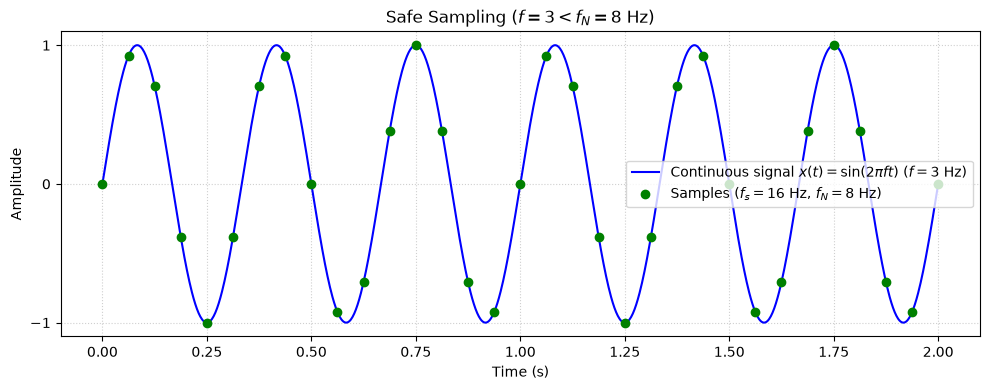

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# --- Parameters จากในรูป ---
f = 3           # Signal frequency: 3 cycles/s
fs = 16         # Sampling rate: 16 samples/s
fN = fs / 2     # Nyquist frequency: 8 cycles/s (Safe: f < fN)
duration = 2.0  # ระยะเวลา 2 วินาที

# --- Signal Generator ---
t_cont = np.linspace(0, duration, 1000)
x_cont = np.sin(2 * np.pi * f * t_cont)

t_sample = np.arange(0, duration + 1/fs, 1/fs)
x_sample = np.sin(2 * np.pi * f * t_sample)

# --- Plot ---
plt.figure(figsize=(10, 4), dpi=100)
plt.plot(t_cont, x_cont, 'b-', label=rf'Continuous signal $x(t)=\sin(2\pi f t)$ ($f={f}$ Hz)')
plt.plot(t_sample, x_sample, 'go', label=f'Samples ($f_s={fs}$ Hz, $f_N={int(fN)}$ Hz)')

plt.title(rf'Safe Sampling ($f = {f} < f_N = {int(fN)}$ Hz)')
plt.xlabel('Time (s)'); plt.ylabel('Amplitude')
plt.xticks(np.arange(0, duration + 0.25, 0.25)); plt.yticks([-1, 0, 1])
plt.grid(True, linestyle=':', alpha=0.6); plt.legend(); plt.tight_layout()
plt.show()


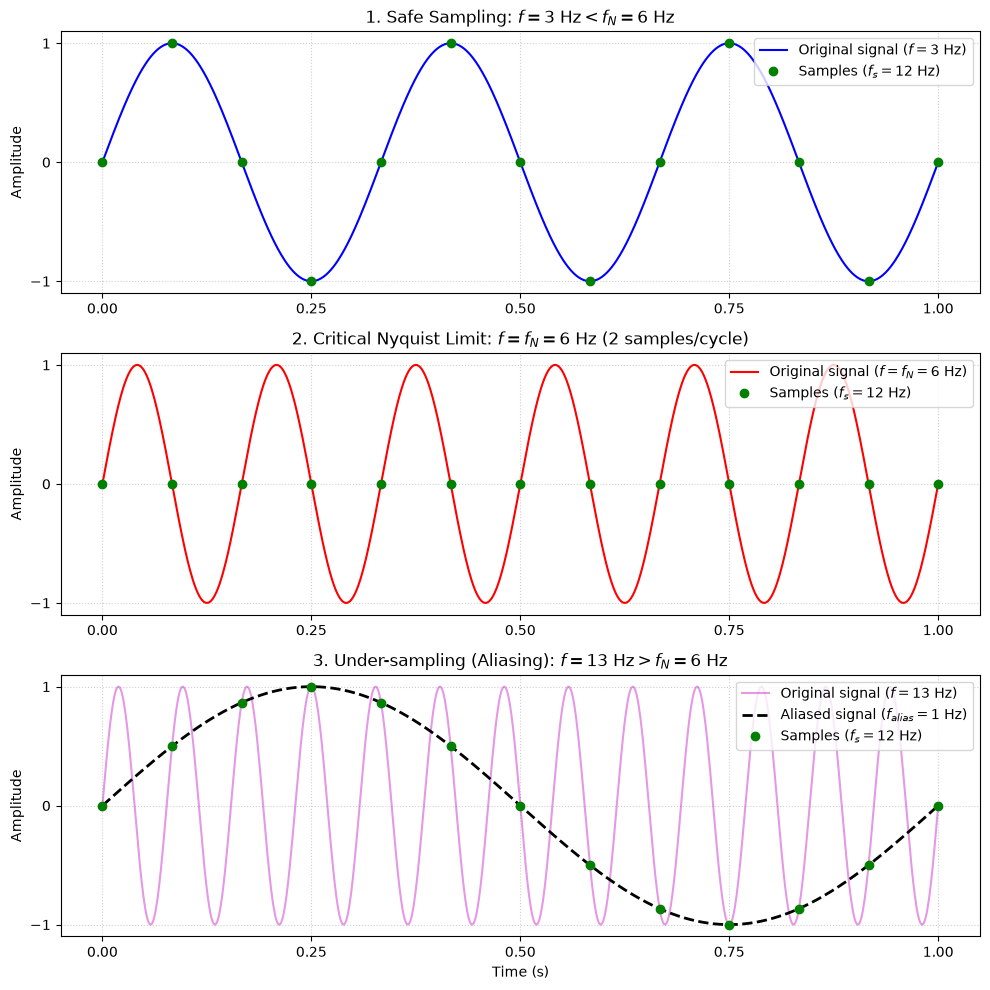

In [20]:
import numpy as np
import matplotlib.pyplot as plt

# --- Parameters ---
fs = 12          # Sampling rate: 16 samples/s
fN = fs / 2      # Nyquist frequency: 8 Hz
duration = 1.0   # ระยะเวลา 2 วินาที

t_cont = np.linspace(0, duration, 1000)
t_sample = np.arange(0, duration + 1/fs, 1/fs)

# 1. Safe Sampling: f1 = 3 Hz (< fN)
f1 = 3
x1_cont = np.sin(2 * np.pi * f1 * t_cont)
x1_sample = np.sin(2 * np.pi * f1 * t_sample)

# 2. Nyquist Limit: f2 = 8 Hz (= fN)
f2 = fN
x2_cont = np.sin(2 * np.pi * f2 * t_cont)
x2_sample = np.sin(2 * np.pi * f2 * t_sample)

# 3. Under-sampling (Aliasing): f3 = 13 Hz (> fN)
f3 = 13
f_alias = abs(f3 - fs)  # ความถี่หลอกที่เกิดขึ้น |13 - 16| = 3 Hz
x3_cont = np.sin(2 * np.pi * f3 * t_cont)
x3_sample = np.sin(2 * np.pi * f3 * t_sample)
x3_alias = np.sin(2 * np.pi * f_alias * t_cont)

# --- Plot 3 Subplots ---
fig, axes = plt.subplots(3, 1, figsize=(10, 10), dpi=100)

# Subplot 1: Safe Sampling
axes[0].plot(t_cont, x1_cont, 'b-', label=rf'Original signal ($f={f1}$ Hz)')
axes[0].plot(t_sample, x1_sample, 'go', label=rf'Samples ($f_s={fs}$ Hz)')
axes[0].set_title(rf'1. Safe Sampling: $f = {f1}\text{{ Hz}} < f_N = {int(fN)}\text{{ Hz}}$')
axes[0].set_ylabel('Amplitude')
axes[0].set_xticks(np.arange(0, duration + 0.25, 0.25)); axes[0].set_yticks([-1, 0, 1])
axes[0].grid(True, linestyle=':', alpha=0.6); axes[0].legend(loc='upper right')

# Subplot 2: Nyquist Limit
axes[1].plot(t_cont, x2_cont, 'r-', label=rf'Original signal ($f=f_N={int(f2)}$ Hz)')
axes[1].plot(t_sample, x2_sample, 'go', label=rf'Samples ($f_s={fs}$ Hz)')
axes[1].set_title(rf'2. Critical Nyquist Limit: $f = f_N = {int(f2)}\text{{ Hz}}$ (2 samples/cycle)')
axes[1].set_ylabel('Amplitude')
axes[1].set_xticks(np.arange(0, duration + 0.25, 0.25)); axes[1].set_yticks([-1, 0, 1])
axes[1].grid(True, linestyle=':', alpha=0.6); axes[1].legend(loc='upper right')

# Subplot 3: Under-sampling (Aliasing)
axes[2].plot(t_cont, x3_cont, 'm-', label=rf'Original signal ($f={f3}$ Hz)', alpha=0.4)
axes[2].plot(t_cont, x3_alias, 'k--', label=rf'Aliased signal ($f_{{alias}}={f_alias}$ Hz)', linewidth=2)
axes[2].plot(t_sample, x3_sample, 'go', label=rf'Samples ($f_s={fs}$ Hz)')
axes[2].set_title(rf'3. Under-sampling (Aliasing): $f = {f3}\text{{ Hz}} > f_N = {int(fN)}\text{{ Hz}}$')
axes[2].set_xlabel('Time (s)'); axes[2].set_ylabel('Amplitude')
axes[2].set_xticks(np.arange(0, duration + 0.25, 0.25)); axes[2].set_yticks([-1, 0, 1])
axes[2].grid(True, linestyle=':', alpha=0.6); axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()